# PPMI Modality Analysis: Clinical Motor Examination & Impairment
**Notebook**: `eda_pca_motor.ipynb`  
**Modality Group**: `motor` (8 Scoped Analyzable Units)  
**Authoritative Scope**: `docs/important_modality_files.md`  
**Cohort Policy (Revision 4)**: Parkinson's disease (`PD`) and Healthy Controls (`HC`) Only  
**PCA Architecture**: Shared-space class-balanced component space fit on 1 deterministic record per participant  
**Governance Framework**: Codex Supervisory Review & `AGENTS.md` Task `EDA-PCA-001`  

---

## Modality Overview
Movement Disorder Society UPDRS Parts I-IV, Schwab & England ADL, and Neuro-QoL mobility/upper extremity assessments.

### Scientific & Governance Invariants
1. **Target Cohort Restriction**: Analytical populations and PCA models are restricted exclusively to verified **Parkinson's disease (`PD`)** and **Healthy Controls (`HC`)**. Excluded classes (SWEDD, prodromal, genetic non-motor carriers) are filtered out prior to analysis. Cohort labels and disease staging fields never enter the PCA feature matrix.
2. **Participant-Level Shared-Space PCA**: For eligible participant-level tables, repeated visits are resolved to 1 record per participant (baseline preferred with stable tie-breaking and completeness checks). PCA and preprocessing (median imputation, scaling) are fit exclusively on a shared, deterministically class-balanced sample ($k = \min(N_{PD}, N_{HC})$, sampled via SHA-256 hash ranking) to reduce direct sample-count influence on component orientation, and all target participants are projected into this identical space.
3. **Comprehensive Committed EDA (Correction C1 / R4-02)**: Exact schemas with variable roles, missingness, duplicate rows, observation grain, numeric skewness, Tukey IQR and z-score outlier metrics, and categorical frequency summaries are visibly rendered in this notebook and committed directly to disk.
4. **Privacy-Safe Displays (Correction C3 / R4-05)**: Scree plots, loadings tables, and 2x2 side-by-side PD vs HC hexbin density score plots with cell suppression ($< 5$ observations masked) and outlier disclosures.
5. **Committed State Reproducibility (Correction C4 / R4-04)**: Loads directly from committed reports (`EDA/outputs/reports/`) using repository-relative POSIX paths with zero dependence on ignored cache.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

# Resolve repository root
repo_root = Path.cwd().resolve()
if (repo_root / "EDA" / "src").exists():
    sys.path.insert(0, str(repo_root / "EDA" / "src"))
elif (repo_root.parent / "EDA" / "src").exists():
    repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "EDA" / "src"))

from ppmi_pipeline.reporting.privacy import PrivacyGuard

print(f"Environment initialized. Modality: 'motor', Dynamic repository root: ppmi")

Environment initialized. Modality: 'motor', Dynamic repository root: ppmi


## 1. Scoped Analyzable Units in Clinical Motor Examination & Impairment
The authoritative catalog assigns exactly **8 analyzable unit(s)** to this modality domain.

In [2]:
manifest_path = repo_root / "EDA" / "outputs" / "reports" / "priority_eda_pca_manifest.json"
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest_data = json.load(f)

mod_units = [u for u in manifest_data["units"] if u.get("modality_group") == 'motor']

inv_rows = []
for unit_entry in mod_units:
    sheet_suffix = (" -> [" + str(unit_entry.get("sheet_name")) + "]") if unit_entry.get("sheet_name") else ""
    pca_stat_str = ("COMPLETED (" + str(unit_entry.get("pca_included_features_count", 0)) + " feats)") if unit_entry.get("pca_status") == "COMPLETED" else str(unit_entry.get("pca_skip_reason"))
    inv_rows.append({
        "Unit Slug": unit_entry["unit_slug"],
        "Filename / Sheet": str(unit_entry.get("declared_filename")) + sheet_suffix,
        "Physical Exists": "Yes" if unit_entry.get("physical_exists") else "No (Absent)",
        "EDA Status": unit_entry.get("eda_status"),
        "PCA Status": unit_entry.get("pca_status"),
        "PCA Reason / Features": pca_stat_str
    })

inv_df = pd.DataFrame(inv_rows)
display(inv_df)
print(f"Total units cataloged: {len(inv_df)} | EDA Completed: {(inv_df['EDA Status'] == 'COMPLETED').sum()} | PCA Completed: {(inv_df['PCA Status'] == 'COMPLETED').sum()}")

,Unit Slug,Filename / Sheet,Physical Exists,EDA Status,PCA Status,PCA Reason / Features
0,MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv,MDS-UPDRS_Part_III_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (33 feats)
1,MOTOR_MDS_UPDRS_Part_II__Patient_Questionnaire...,MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov...,Yes,COMPLETED,COMPLETED,COMPLETED (13 feats)
2,MOTOR_MDS-UPDRS_Part_I_09Nov2026_csv,MDS-UPDRS_Part_I_09Nov2026.csv,Yes,COMPLETED,COMPLETED,COMPLETED (6 feats)
3,MOTOR_MDS-UPDRS_Part_I_Patient_Questionnaire_0...,MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov20...,Yes,COMPLETED,COMPLETED,COMPLETED (7 feats)
4,MOTOR_MDS-UPDRS_Part_IV__Motor_Complications_0...,MDS-UPDRS_Part_IV_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Class lacks within-cohort multivariate varianc...
5,MOTOR_Modified_Schwab___England_Activities_of_...,Modified_Schwab___England_Activities_of_Daily_...,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
6,MOTOR_Neuro_QoL__Lower_Extremity_Function__Mob...,Neuro_QoL__Lower_Extremity_Function__Mobility_...,Yes,COMPLETED,COMPLETED,COMPLETED (8 feats)
7,MOTOR_Neuro_QoL__Upper_Extremity_Function_-_Sh...,Neuro_QoL__Upper_Extremity_Function_-_Short_Fo...,Yes,COMPLETED,COMPLETED,COMPLETED (8 feats)


Total units cataloged: 8 | EDA Completed: 8 | PCA Completed: 6


---
## 2.1. Unit: `MDS-UPDRS_Part_III_09Nov2026.csv` 
- **Unit Slug**: `MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv`
- **Source Path**: `MOTOR/MDS-UPDRS_Part_III_09Nov2026.csv`
- **Committed Unit Artifact**: [`MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv.json`](../EDA/outputs/reports/units/MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID, PDSTATE)`
- **Selection Tier**: `Primary EDA` | **Role**: `Objective clinician motor examination covering speech, facial expression, rest tremor, postural tremor, kinetic tremor, rigidity, finger tapping, hand movements, pronation-supination, toe tapping, leg agility, gait, posture, and bradykinesia. Differentiates `ON` vs. `OFF` levodopa states.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: MOTOR/MDS-UPDRS_Part_III_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 24,755 analyzed rows x 66 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 40,609 (5,558 participants)
  - PD Retained:  21,981 rows (1,684 participants)
  - HC Retained:  2,774 rows (336 participants)
  - Non-Target Excluded: 15,208 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  646 rows

Exact Variable Schema & Storage Types (66 columns):
Showing first 20 of 66 columns (complete schema committed to MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"24,755",Identifier
1,PATNO,int64,0,0.0%,"2,020",Identifier
2,EVENT_ID,object,0,0.0%,40,Identifier
3,PAG_NAME,object,0,0.0%,5,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,PDTRTMNT,float64,"1,763",7.1%,2,Date / Timestamp / Visit
6,PDSTATE,object,"7,691",31.1%,2,Categorical / Text
7,HRPOSTMED,float64,"10,157",41.0%,"1,299",Analytical Numeric Measurement
8,HRDBSON,float64,"24,306",98.2%,280,Analytical Numeric Measurement
9,HRDBSOFF,float64,"24,613",99.4%,58,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,50
Date / Timestamp / Visit,6
Categorical / Text,4
Identifier,3
Administrative Metadata,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 419,152 / 1,633,830 (25.65%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (58 total, top 8):


,name,missing_count,missing_percent,variable_role
15,DBSOFFYN,"24,683",99.7%,Analytical Numeric Measurement
9,HRDBSOFF,"24,613",99.4%,Analytical Numeric Measurement
16,DBSOFFTM,"24,600",99.4%,Categorical / Text
18,ONNORSN,"24,425",98.7%,Analytical Numeric Measurement
8,HRDBSON,"24,306",98.2%,Analytical Numeric Measurement
21,DBSONTM,"24,292",98.1%,Categorical / Text
20,DBSONYN,"24,228",97.9%,Analytical Numeric Measurement
14,OFFNORSN,"22,894",92.5%,Analytical Numeric Measurement


... (4 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"21,981"
1,HC,"2,774"



Numeric Summaries & Outlier Diagnostics (51 continuous/discrete features):
Showing top 10 of 51 features (full distribution profiles in MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,PDTRTMNT,0.742,0.438,0.000,1.000,1.000,-1.104,Strongly skewed (negative),0,0
1,HRPOSTMED,30.721,1671.409,-94.833,3.000,175321.383,92.376,Strongly skewed (positive),119,9
2,HRDBSON,7.163,5.451,-10.767,9.417,17.000,-0.129,Approximately symmetric,0,1
3,HRDBSOFF,0.629,1.905,-14.033,0.300,9.000,-2.649,Strongly skewed (negative),9,4
4,PDMEDYN,0.738,0.440,0.000,1.000,1.000,-1.083,Strongly skewed (negative),0,0
5,DBSYN,0.059,0.235,0.000,0.000,1.000,3.750,Strongly skewed (positive),"1,453","1,453"
6,ONOFFORDER,1.349,0.477,1.000,1.000,2.000,0.636,Moderately skewed (positive),0,0
7,OFFEXAM,0.607,0.488,0.000,1.000,1.000,-0.439,Approximately symmetric,0,0
8,OFFNORSN,4.707,3.155,1.000,3.000,9.000,0.247,Approximately symmetric,0,0
9,DBSOFFYN,0.986,0.118,0.000,1.000,1.000,-8.485,Strongly skewed (negative),1,1


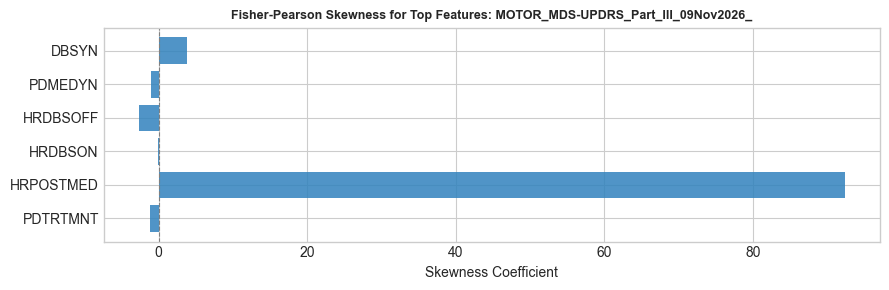

In [3]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MOTOR/MDS-UPDRS_Part_III_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MOTOR_MDS-UPDRS_Part_III_09Nov2026_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `33` continuous analytical measurements
- **Excluded Features**: `33` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `35.1%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,684 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,020


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,35.11%,35.11%
1,PC2,8.65%,43.76%
2,PC3,6.81%,50.58%
3,PC4,4.99%,55.57%
4,PC5,3.73%,59.31%



Top PC1 Feature Loadings:


,feature_name,loading
0,NP3BRADY,0.2453
1,NP3FACXP,0.2325
2,NP3FTAPL,0.2235
3,NP3HMOVR,0.2212
4,NP3FTAPR,0.2212


Scree & Eigenvector Loadings Plot:


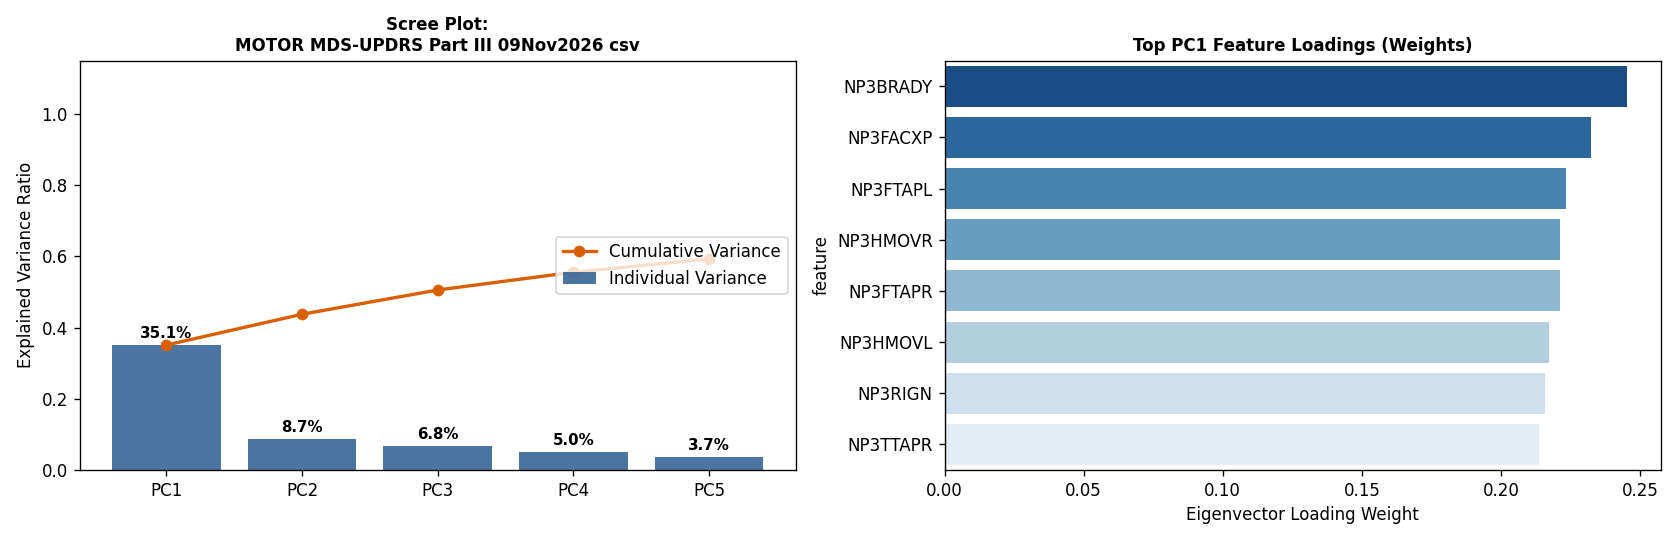

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


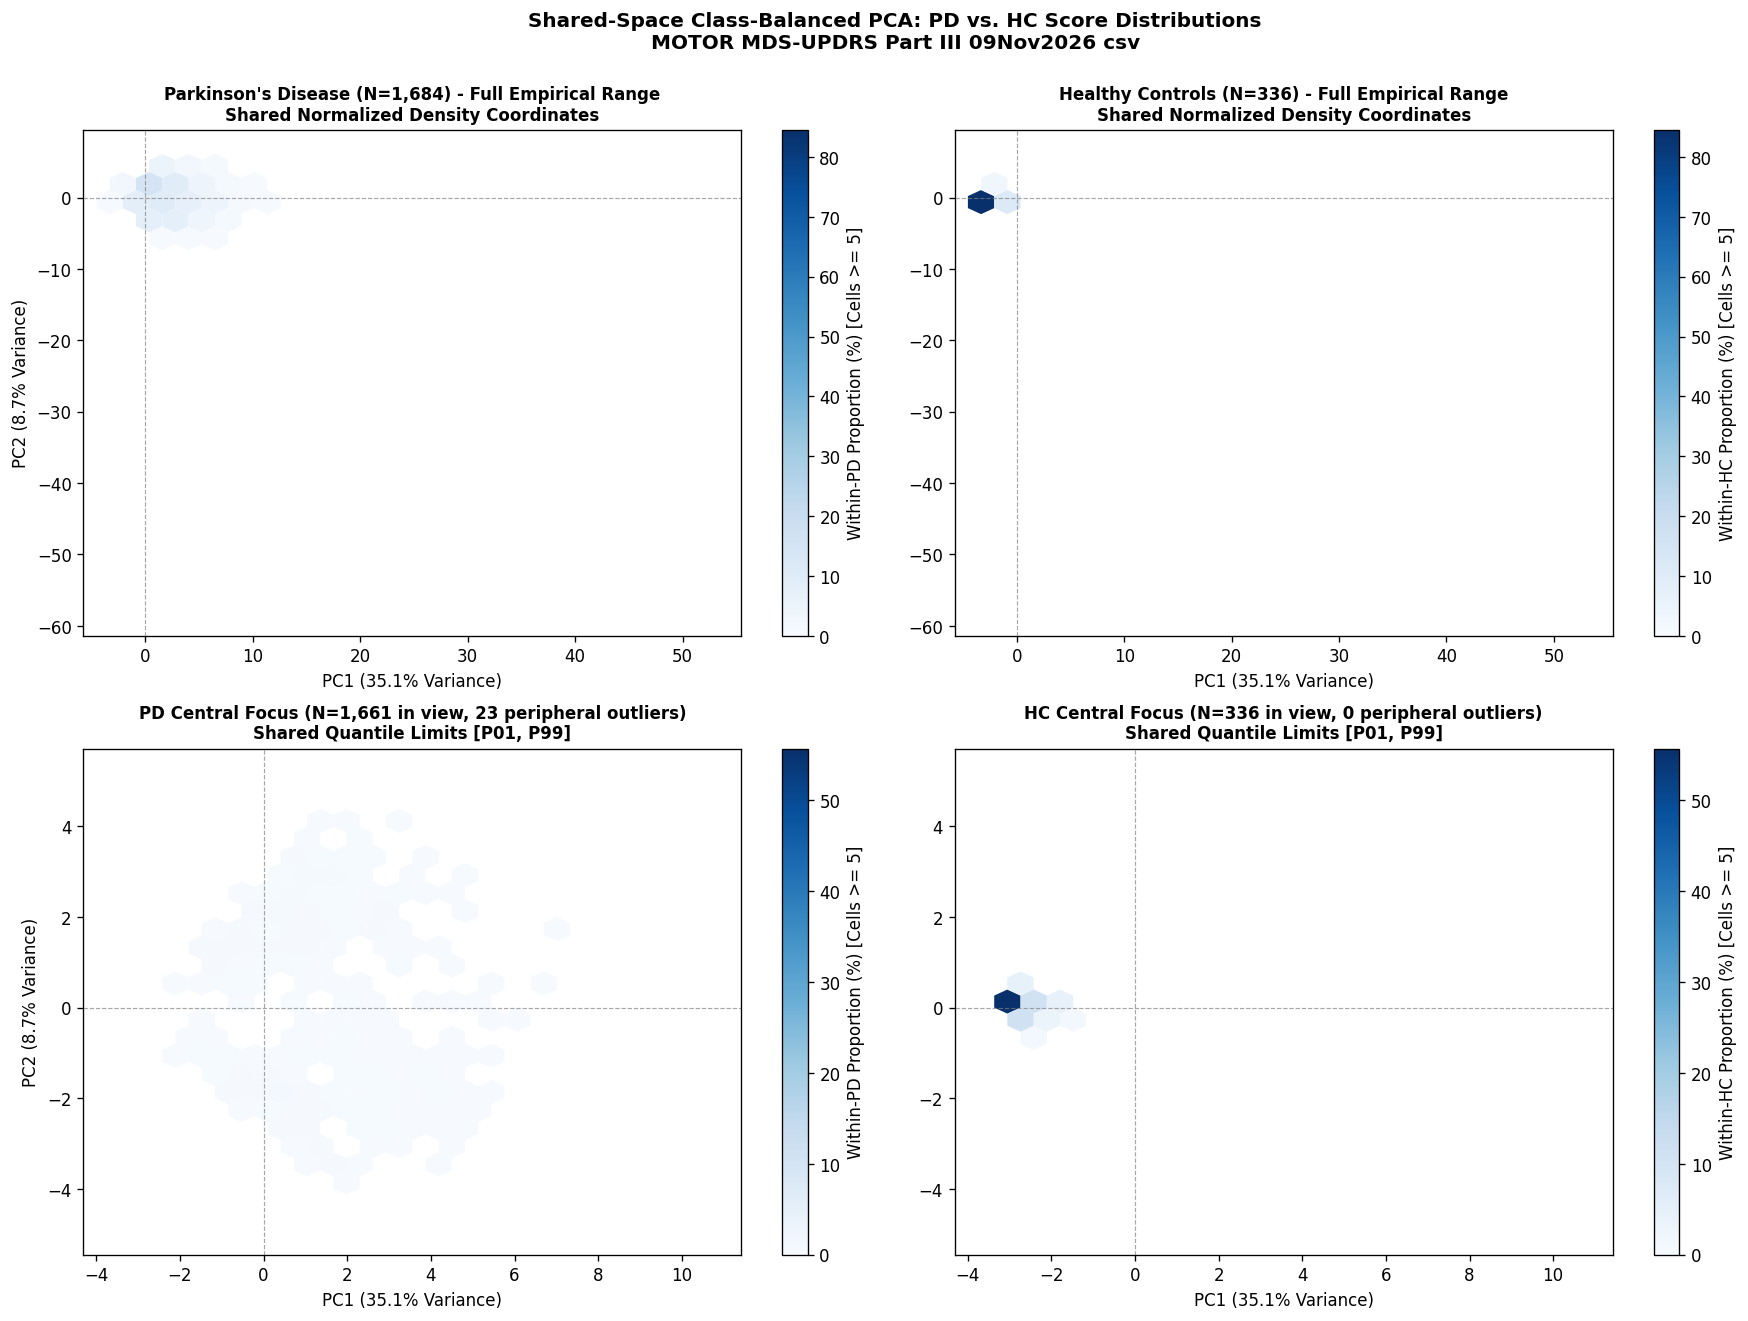

In [4]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/MOTOR_MDS-UPDRS_Part_III_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.2. Unit: `MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026.csv` 
- **Unit Slug**: `MOTOR_MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026_csv`
- **Source Path**: `MOTOR/MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026.csv`
- **Committed Unit Artifact**: [`MOTOR_MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026_csv.json`](../EDA/outputs/reports/units/MOTOR_MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Motor Experiences of Daily Living (M-EDL). Patient-reported impact on speech, swallowing, dressing, eating, hygiene, turning in bed, and walking.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: MOTOR/MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 19,987 analyzed rows x 23 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 39,521 (5,552 participants)
  - PD Retained:  16,848 rows (1,684 participants)
  - HC Retained:  3,139 rows (336 participants)
  - Non-Target Excluded: 18,959 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  575 rows

Exact Variable Schema & Storage Types (23 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"19,987",Identifier
1,PATNO,int64,0,0.0%,"2,020",Identifier
2,EVENT_ID,object,0,0.0%,42,Identifier
3,PAG_NAME,object,0,0.0%,2,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,NUPSOURC,int64,0,0.0%,3,Analytical Numeric Measurement
6,NP2SPCH,float64,4,0.0%,5,Analytical Numeric Measurement
7,NP2SALV,float64,5,0.0%,5,Analytical Numeric Measurement
8,NP2SWAL,float64,8,0.0%,5,Analytical Numeric Measurement
9,NP2EAT,float64,10,0.1%,5,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,15
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 149 / 459,701 (0.03%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (14 total, top 8):


,name,missing_count,missing_percent,variable_role
19,NP2PTOT,30,0.1%,Analytical Numeric Measurement
13,NP2HOBB,15,0.1%,Analytical Numeric Measurement
12,NP2HWRT,11,0.1%,Analytical Numeric Measurement
17,NP2WALK,11,0.1%,Analytical Numeric Measurement
18,NP2FREZ,11,0.1%,Analytical Numeric Measurement
10,NP2DRES,10,0.1%,Analytical Numeric Measurement
9,NP2EAT,10,0.1%,Analytical Numeric Measurement
15,NP2TRMR,9,0.1%,Analytical Numeric Measurement


... (2 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"16,848"
1,HC,"3,139"



Numeric Summaries & Outlier Diagnostics (15 continuous/discrete features):
Showing top 10 of 15 features (full distribution profiles in MOTOR_MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,NUPSOURC,1.108,0.445,1.0,1.0,3.0,3.954,Strongly skewed (positive),"1,131","1,020"
1,NP2SPCH,0.675,0.921,0.0,0.0,4.0,1.205,Strongly skewed (positive),"1,055",97
2,NP2SALV,0.745,1.075,0.0,0.0,4.0,1.227,Strongly skewed (positive),"1,944",329
3,NP2SWAL,0.289,0.603,0.0,0.0,4.0,2.442,Strongly skewed (positive),"4,565",346
4,NP2EAT,0.469,0.698,0.0,0.0,4.0,1.460,Strongly skewed (positive),223,223
5,NP2DRES,0.630,0.791,0.0,0.0,4.0,1.241,Strongly skewed (positive),437,119
6,NP2HYGN,0.382,0.631,0.0,0.0,4.0,2.050,Strongly skewed (positive),257,257
7,NP2HWRT,1.070,1.130,0.0,1.0,4.0,0.843,Moderately skewed (positive),0,0
8,NP2HOBB,0.691,0.941,0.0,0.0,4.0,1.431,Strongly skewed (positive),"1,128",346
9,NP2TURN,0.550,0.766,0.0,0.0,4.0,1.690,Strongly skewed (positive),546,546


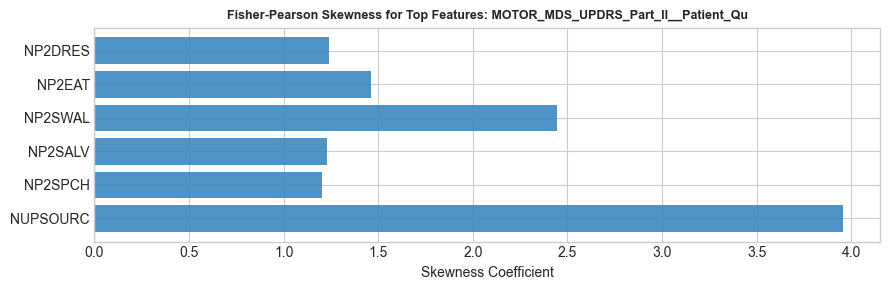

In [5]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MOTOR_MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MOTOR/MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MOTOR_MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MOTOR_MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MOTOR_MDS_UPDRS_Part_II__Patient_Qu", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `13` continuous analytical measurements
- **Excluded Features**: `10` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `42.8%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,684 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,020


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,42.79%,42.79%
1,PC2,8.45%,51.24%
2,PC3,7.35%,58.59%
3,PC4,6.43%,65.02%
4,PC5,5.57%,70.59%



Top PC1 Feature Loadings:


,feature_name,loading
0,NP2RISE,0.3210
1,NP2DRES,0.3188
2,NP2WALK,0.3075
3,NP2HYGN,0.2993
4,NP2HOBB,0.2964


Scree & Eigenvector Loadings Plot:


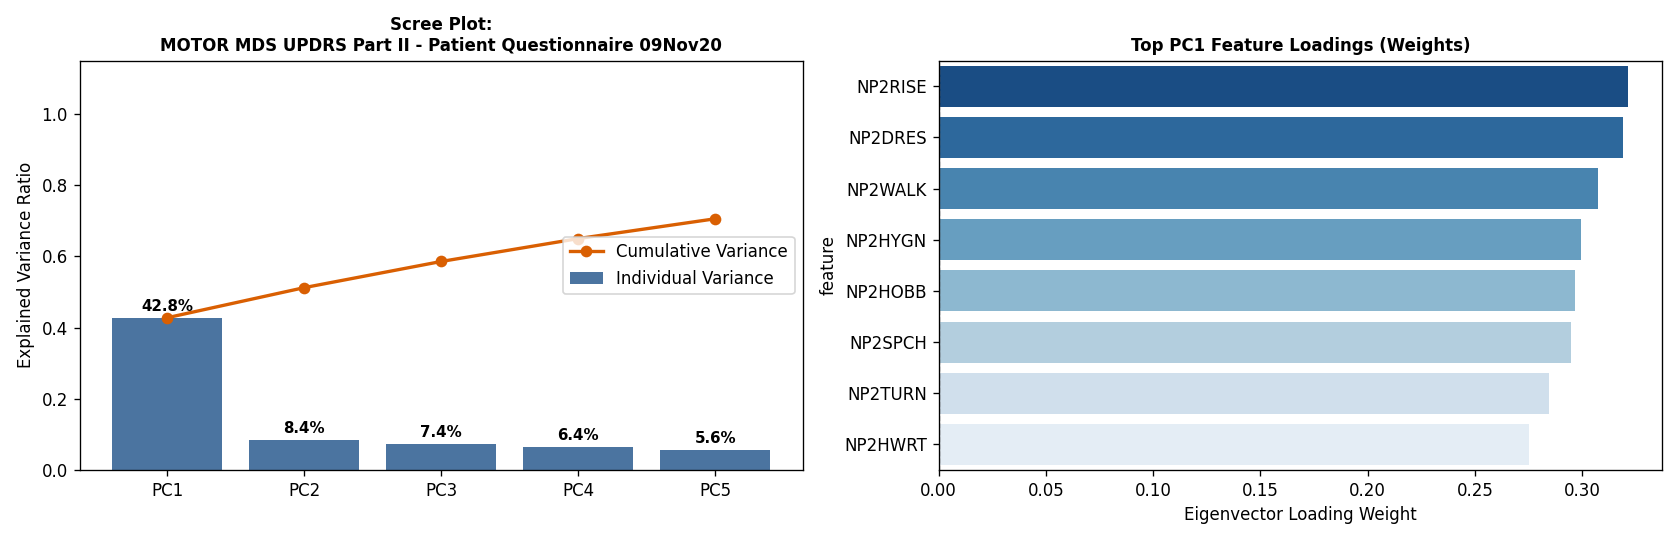

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


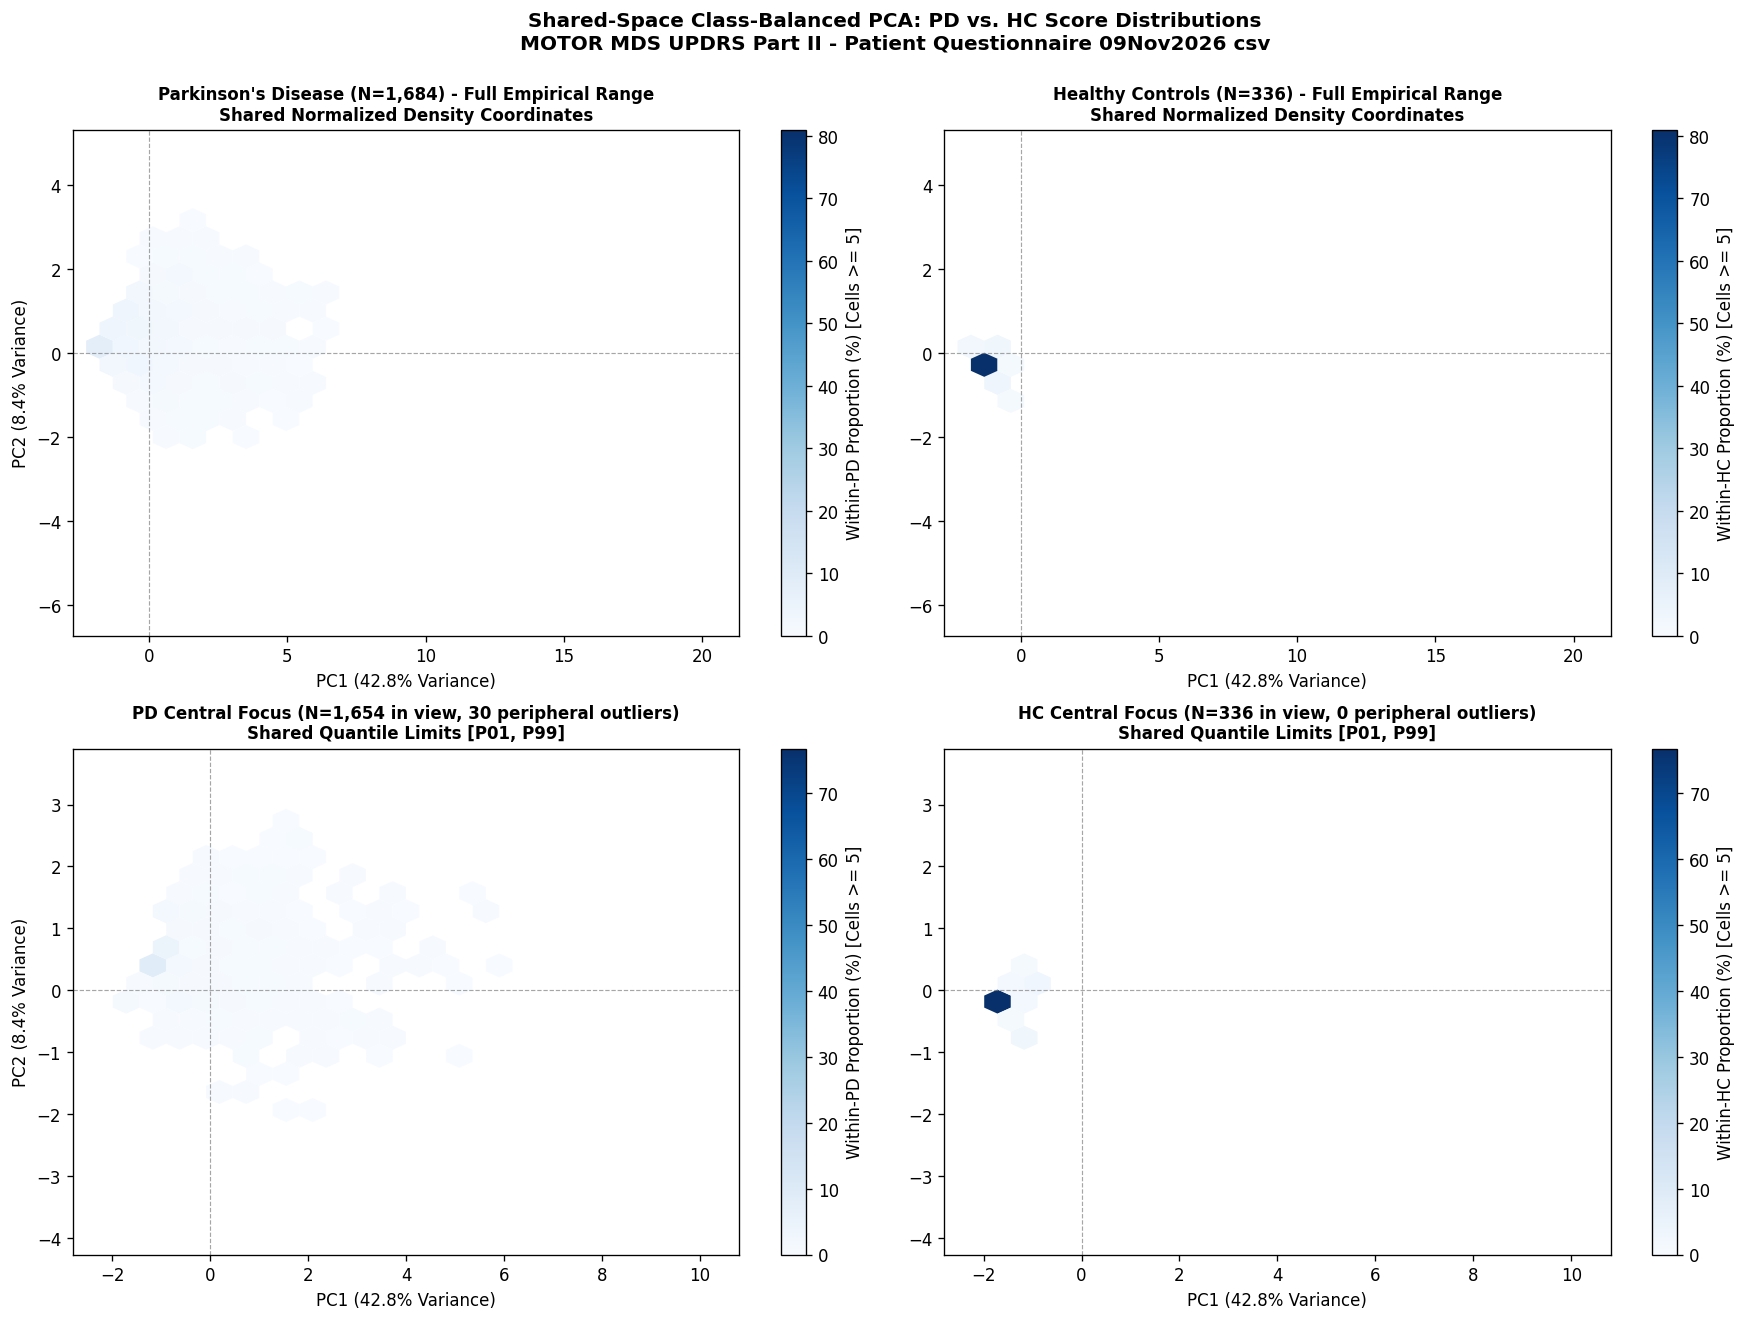

In [6]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/MOTOR_MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/MOTOR_MDS_UPDRS_Part_II__Patient_Questionnaire_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.3. Unit: `MDS-UPDRS_Part_I_09Nov2026.csv` 
- **Unit Slug**: `MOTOR_MDS-UPDRS_Part_I_09Nov2026_csv`
- **Source Path**: `MOTOR/MDS-UPDRS_Part_I_09Nov2026.csv`
- **Committed Unit Artifact**: [`MOTOR_MDS-UPDRS_Part_I_09Nov2026_csv.json`](../EDA/outputs/reports/units/MOTOR_MDS-UPDRS_Part_I_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Clinician-administered evaluation of Non-Motor Experiences of Daily Living (cognitive impairment, hallucinations, depressed mood, anxious mood, apathy, dopamine dysregulation syndrome).`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: MOTOR/MDS-UPDRS_Part_I_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 18,574 analyzed rows x 16 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 34,314 (5,553 participants)
  - PD Retained:  15,690 rows (1,684 participants)
  - HC Retained:  2,884 rows (336 participants)
  - Non-Target Excluded: 15,168 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  572 rows

Exact Variable Schema & Storage Types (16 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"18,574",Identifier
1,PATNO,int64,0,0.0%,"2,020",Identifier
2,EVENT_ID,object,0,0.0%,41,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,NUPSOURC,float64,1,0.0%,3,Analytical Numeric Measurement
6,NP1COG,int64,0,0.0%,6,Analytical Numeric Measurement
7,NP1HALL,int64,0,0.0%,6,Analytical Numeric Measurement
8,NP1DPRS,float64,0,0.0%,6,Analytical Numeric Measurement
9,NP1ANXS,float64,1,0.0%,6,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,8
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 54 / 297,184 (0.02%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (5 total, top 8):


,name,missing_count,missing_percent,variable_role
12,NP1RTOT,48,0.3%,Analytical Numeric Measurement
11,NP1DDS,3,0.0%,Analytical Numeric Measurement
5,NUPSOURC,1,0.0%,Analytical Numeric Measurement
10,NP1APAT,1,0.0%,Analytical Numeric Measurement
9,NP1ANXS,1,0.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"15,690"
1,HC,"2,884"



Numeric Summaries & Outlier Diagnostics (8 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,NUPSOURC,1.164,0.545,1.0,1.0,3.0,3.052,Strongly skewed (positive),"1,548","1,490"
1,NP1COG,0.492,2.085,0.0,0.0,101.0,42.297,Strongly skewed (positive),453,7
2,NP1HALL,0.149,1.859,0.0,0.0,101.0,51.611,Strongly skewed (positive),"1,678",6
3,NP1DPRS,0.469,2.661,0.0,0.0,101.0,34.879,Strongly skewed (positive),522,12
4,NP1ANXS,0.547,2.226,0.0,0.0,101.0,39.670,Strongly skewed (positive),612,8
5,NP1APAT,0.397,2.653,0.0,0.0,101.0,35.273,Strongly skewed (positive),"4,145",12
6,NP1DDS,0.258,4.328,0.0,0.0,101.0,23.098,Strongly skewed (positive),"1,021",34
7,NP1RTOT,1.880,2.419,0.0,1.0,20.0,2.056,Strongly skewed (positive),707,303


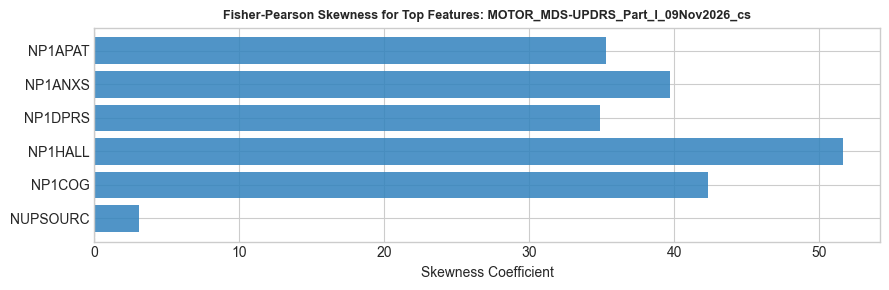

In [7]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MOTOR_MDS-UPDRS_Part_I_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MOTOR/MDS-UPDRS_Part_I_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MOTOR_MDS-UPDRS_Part_I_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MOTOR_MDS-UPDRS_Part_I_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MOTOR_MDS-UPDRS_Part_I_09Nov2026_cs", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `6` continuous analytical measurements
- **Excluded Features**: `10` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `36.0%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,684 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,020


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,35.98%,35.98%
1,PC2,17.49%,53.46%
2,PC3,16.43%,69.90%
3,PC4,12.28%,82.17%
4,PC5,10.82%,93.00%



Top PC1 Feature Loadings:


,feature_name,loading
0,NP1DPRS,0.5497
1,NP1APAT,0.5093
2,NP1ANXS,0.4714
3,NP1COG,0.3973
4,NP1HALL,0.2417


Scree & Eigenvector Loadings Plot:


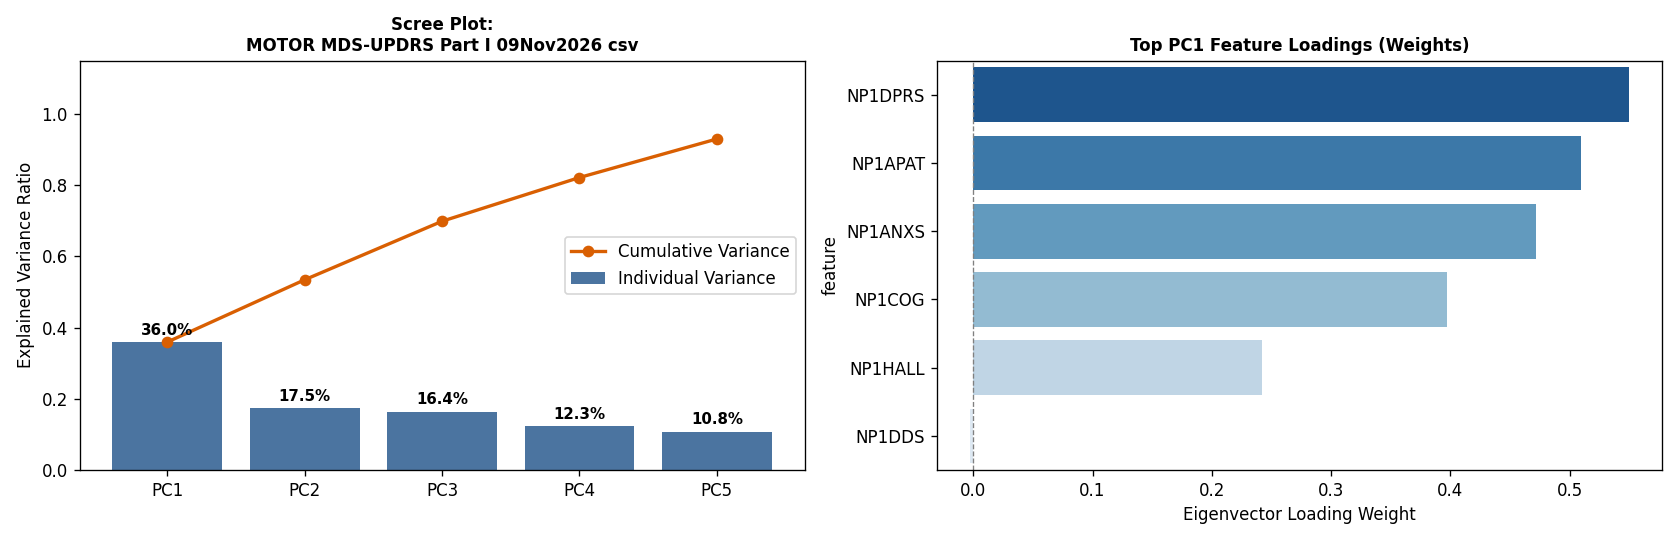

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


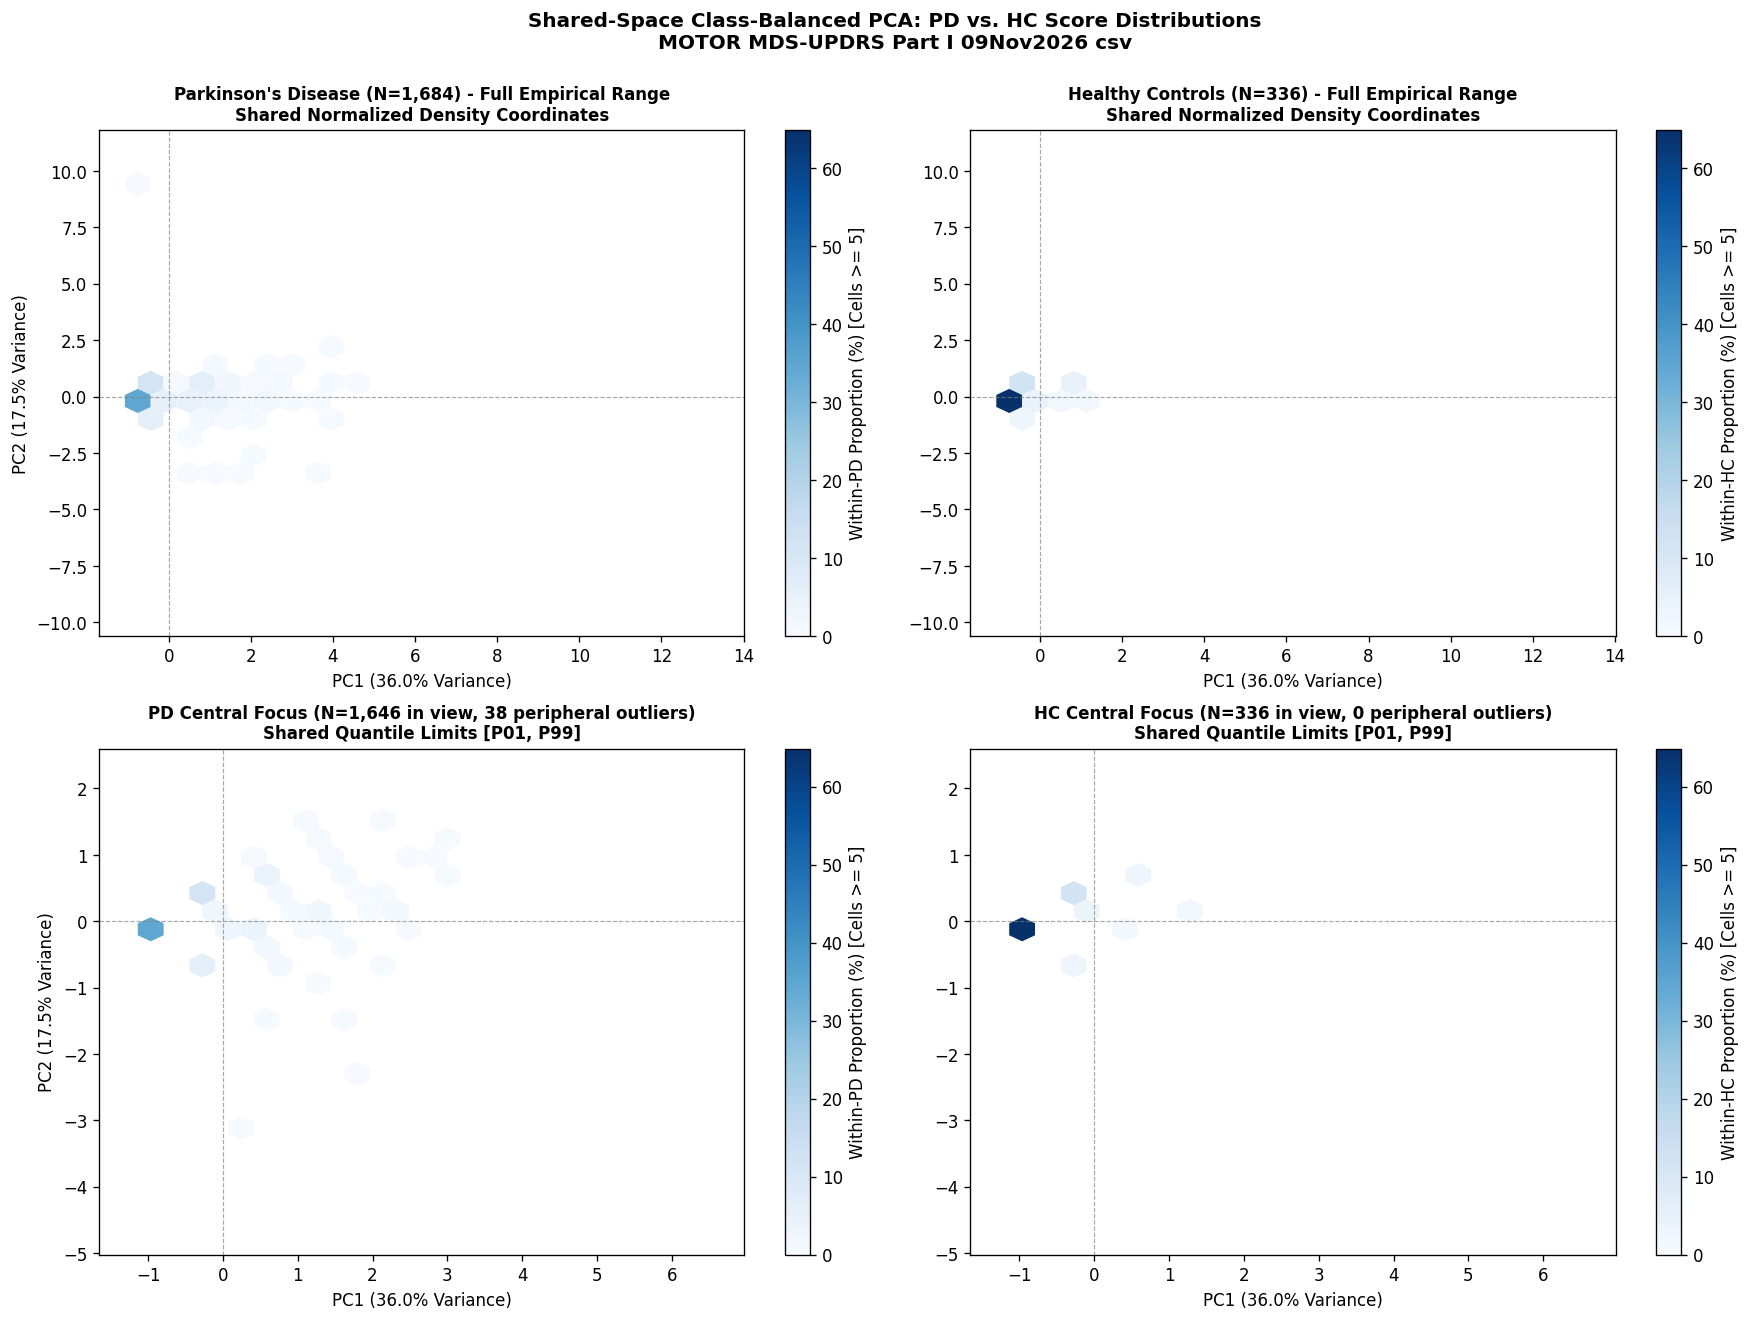

In [8]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/MOTOR_MDS-UPDRS_Part_I_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/MOTOR_MDS-UPDRS_Part_I_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.4. Unit: `MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026.csv` 
- **Unit Slug**: `MOTOR_MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026_csv`
- **Source Path**: `MOTOR/MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026.csv`
- **Committed Unit Artifact**: [`MOTOR_MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026_csv.json`](../EDA/outputs/reports/units/MOTOR_MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Patient-reported Non-Motor Experiences of Daily Living (sleep problems, daytime sleepiness, pain, urinary problems, constipation, lightheadedness, fatigue).`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: MOTOR/MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 19,986 analyzed rows x 17 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 39,520 (5,552 participants)
  - PD Retained:  16,847 rows (1,684 participants)
  - HC Retained:  3,139 rows (336 participants)
  - Non-Target Excluded: 18,959 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  575 rows

Exact Variable Schema & Storage Types (17 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"19,986",Identifier
1,PATNO,int64,0,0.0%,"2,020",Identifier
2,EVENT_ID,object,0,0.0%,42,Identifier
3,PAG_NAME,object,0,0.0%,2,Administrative Metadata
4,INFODT,object,0,0.0%,194,Date / Timestamp / Visit
5,NUPSOURC,int64,0,0.0%,3,Analytical Numeric Measurement
6,NP1SLPN,float64,3,0.0%,5,Analytical Numeric Measurement
7,NP1SLPD,float64,4,0.0%,5,Analytical Numeric Measurement
8,NP1PAIN,float64,7,0.0%,5,Analytical Numeric Measurement
9,NP1URIN,float64,4,0.0%,5,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,9
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 37 / 339,762 (0.01%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (8 total, top 8):


,name,missing_count,missing_percent,variable_role
8,NP1PAIN,7,0.0%,Analytical Numeric Measurement
13,NP1PTOT,8,0.0%,Analytical Numeric Measurement
7,NP1SLPD,4,0.0%,Analytical Numeric Measurement
6,NP1SLPN,3,0.0%,Analytical Numeric Measurement
9,NP1URIN,4,0.0%,Analytical Numeric Measurement
10,NP1CNST,3,0.0%,Analytical Numeric Measurement
11,NP1LTHD,4,0.0%,Analytical Numeric Measurement
12,NP1FATG,4,0.0%,Analytical Numeric Measurement


... (2 outputs left out)

  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"16,847"
1,HC,"3,139"



Numeric Summaries & Outlier Diagnostics (9 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,NUPSOURC,1.110,0.449,1.0,1.0,3.0,3.908,Strongly skewed (positive),"1,155","1,039"
1,NP1SLPN,1.173,1.159,0.0,1.0,4.0,0.615,Moderately skewed (positive),0,0
2,NP1SLPD,0.952,0.898,0.0,1.0,4.0,0.450,Approximately symmetric,0,83
3,NP1PAIN,0.903,0.990,0.0,1.0,4.0,1.069,Strongly skewed (positive),"1,777",350
4,NP1URIN,0.841,0.981,0.0,1.0,4.0,1.134,Strongly skewed (positive),"1,521",346
5,NP1CNST,0.632,0.869,0.0,0.0,4.0,1.333,Strongly skewed (positive),998,67
6,NP1LTHD,0.431,0.743,0.0,0.0,4.0,1.870,Strongly skewed (positive),506,506
7,NP1FATG,0.826,0.939,0.0,1.0,4.0,1.133,Strongly skewed (positive),"1,251",301
8,NP1PTOT,5.757,4.131,0.0,5.0,25.0,0.861,Moderately skewed (positive),489,140


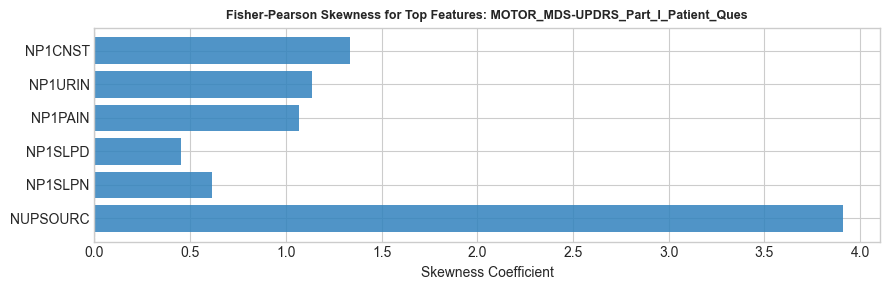

In [9]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MOTOR_MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MOTOR/MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MOTOR_MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MOTOR_MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MOTOR_MDS-UPDRS_Part_I_Patient_Ques", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `7` continuous analytical measurements
- **Excluded Features**: `10` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `38.7%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,684 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,020


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,38.71%,38.71%
1,PC2,11.95%,50.66%
2,PC3,11.63%,62.29%
3,PC4,11.03%,73.32%
4,PC5,9.89%,83.21%



Top PC1 Feature Loadings:


,feature_name,loading
0,NP1FATG,0.4634
1,NP1SLPN,0.3850
2,NP1CNST,0.3750
3,NP1SLPD,0.3583
4,NP1PAIN,0.3529


Scree & Eigenvector Loadings Plot:


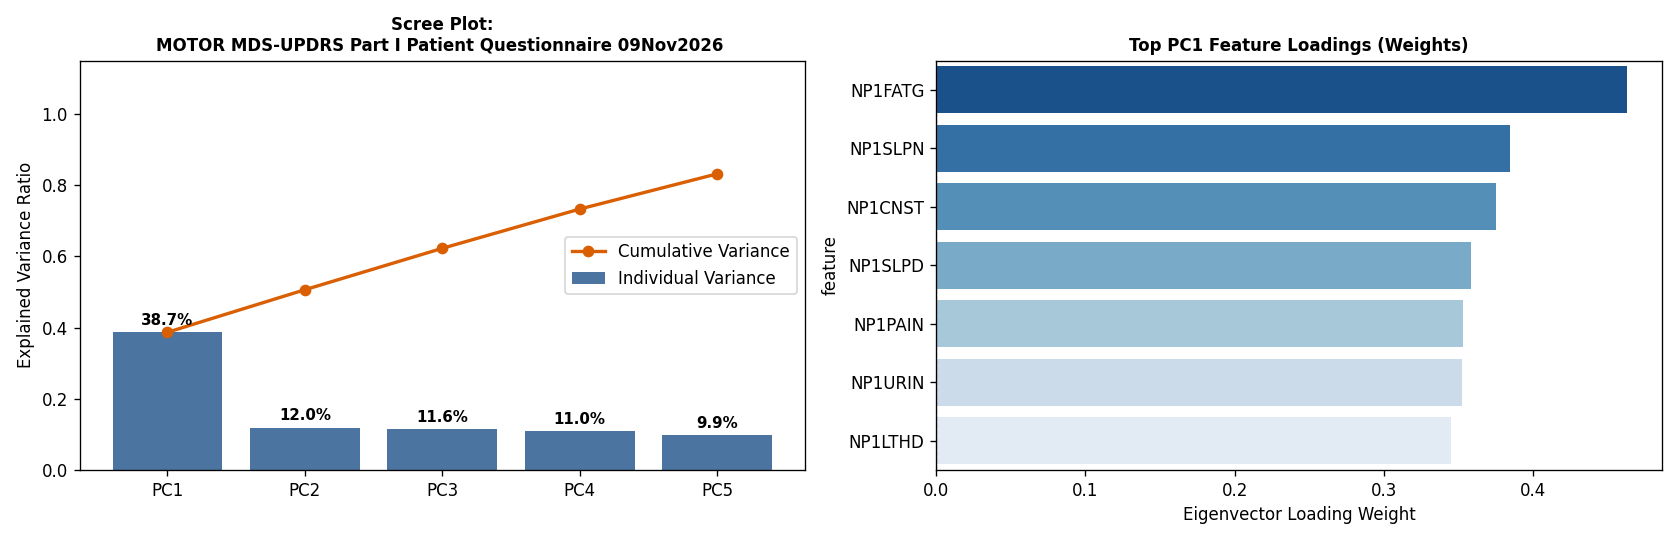

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


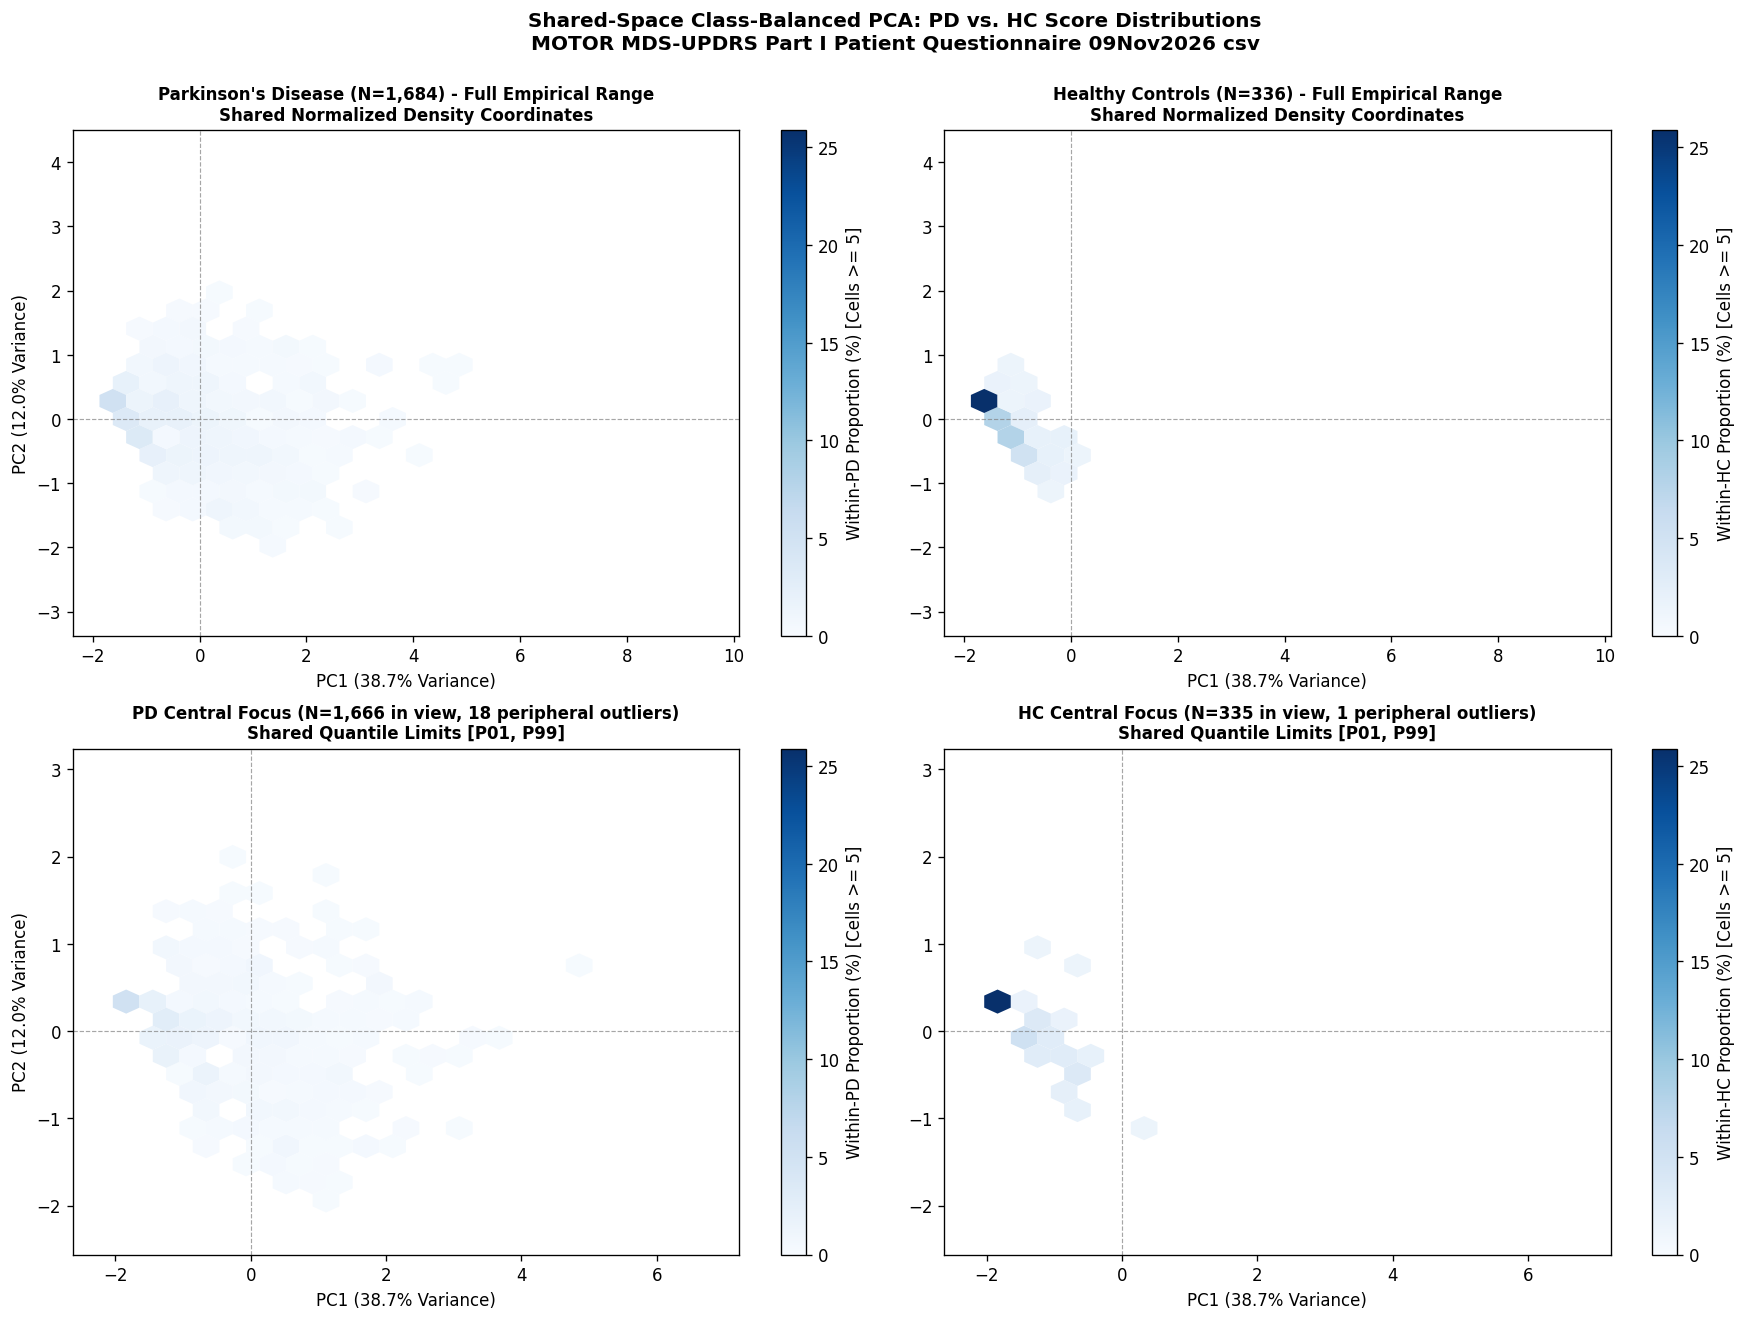

In [10]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/MOTOR_MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/MOTOR_MDS-UPDRS_Part_I_Patient_Questionnaire_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.5. Unit: `MDS-UPDRS_Part_IV_09Nov2026.csv` 
- **Unit Slug**: `MOTOR_MDS-UPDRS_Part_IV__Motor_Complications_09Nov2026_csv`
- **Source Path**: `MOTOR/MDS-UPDRS_Part_IV__Motor_Complications_09Nov2026.csv`
- **Committed Unit Artifact**: [`MOTOR_MDS-UPDRS_Part_IV__Motor_Complications_09Nov2026_csv.json`](../EDA/outputs/reports/units/MOTOR_MDS-UPDRS_Part_IV__Motor_Complications_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Motor Complications: time spent with dyskinesias, dyskinesia-related disability, time in "OFF" state, motor fluctuations, and early morning dystonia.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: MOTOR/MDS-UPDRS_Part_IV__Motor_Complications_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 10,735 analyzed rows x 24 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 11,461 (1,818 participants)
  - PD Retained:  10,693 rows (1,504 participants)
  - HC Retained:  42 rows (19 participants)
  - Non-Target Excluded: 662 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  64 rows

Exact Variable Schema & Storage Types (24 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"10,735",Identifier
1,PATNO,int64,0,0.0%,"1,523",Identifier
2,EVENT_ID,object,0,0.0%,40,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,184,Date / Timestamp / Visit
5,NP4WDYSK,int64,0,0.0%,6,Analytical Numeric Measurement
6,NP4WDYSKDEN,float64,"5,582",52.0%,21,Analytical Numeric Measurement
7,NP4WDYSKNUM,float64,"5,593",52.1%,23,Analytical Numeric Measurement
8,NP4WDYSKPCT,float64,"5,617",52.3%,72,Analytical Numeric Measurement
9,NP4DYSKI,int64,0,0.0%,6,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,16
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 53,138 / 257,640 (20.62%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (14 total, top 8):


,name,missing_count,missing_percent,variable_role
19,NP4DYSTNPCT,"8,224",76.6%,Analytical Numeric Measurement
13,NP4OFFPCT,"5,625",52.4%,Analytical Numeric Measurement
8,NP4WDYSKPCT,"5,617",52.3%,Analytical Numeric Measurement
17,NP4DYSTNDEN,"5,613",52.3%,Analytical Numeric Measurement
18,NP4DYSTNNUM,"5,609",52.2%,Analytical Numeric Measurement
12,NP4OFFNUM,"5,599",52.2%,Analytical Numeric Measurement
11,NP4OFFDEN,"5,595",52.1%,Analytical Numeric Measurement
7,NP4WDYSKNUM,"5,593",52.1%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"10,693"
1,HC,42



Numeric Summaries & Outlier Diagnostics (16 continuous/discrete features):


Showing top 10 of 16 features (full distribution profiles in MOTOR_MDS-UPDRS_Part_IV__Motor_Complications_09Nov2026_csv.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,NP4WDYSK,0.471,3.700,0.0,0.0,101.0,26.178,Strongly skewed (positive),"2,638",14
1,NP4WDYSKDEN,0.978,2.366,-2.0,0.0,20.0,3.747,Strongly skewed (positive),618,131
2,NP4WDYSKNUM,16.438,2.116,0.0,16.0,23.0,-3.019,Strongly skewed (negative),182,106
3,NP4WDYSKPCT,6.121,15.212,-13.0,0.0,200.0,4.550,Strongly skewed (positive),635,126
4,NP4DYSKI,0.306,3.549,0.0,0.0,101.0,27.674,Strongly skewed (positive),"1,370",13
5,NP4OFF,0.762,4.899,0.0,0.0,101.0,19.961,Strongly skewed (positive),211,25
6,NP4OFFDEN,1.545,2.436,-2.0,0.0,20.0,2.693,Strongly skewed (positive),334,106
7,NP4OFFNUM,16.480,2.889,0.0,16.0,160.0,22.734,Strongly skewed (positive),175,51
8,NP4OFFPCT,9.763,16.525,-13.0,0.0,367.0,5.020,Strongly skewed (positive),376,71
9,NP4FLCTI,0.843,5.216,0.0,0.0,101.0,18.482,Strongly skewed (positive),895,28


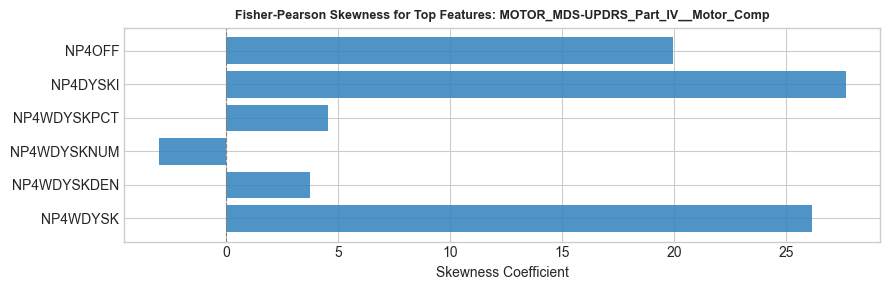

In [11]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MOTOR_MDS-UPDRS_Part_IV__Motor_Complications_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MOTOR/MDS-UPDRS_Part_IV__Motor_Complications_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MOTOR_MDS-UPDRS_Part_IV__Motor_Complications_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MOTOR_MDS-UPDRS_Part_IV__Motor_Complications_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MOTOR_MDS-UPDRS_Part_IV__Motor_Comp", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Class lacks within-cohort multivariate variance (healthy controls invariant across clinical complication features)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [12]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Class lacks within-cohort multivariate variance (healthy controls invariant across clinical complication features)
Features Evaluated: 7 included, 17 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,INFODT,"Identifier, date, visit, demographic, instrume..."
5,NP4WDYSKDEN,Excessive missingness (52.0% > 40%)
6,NP4WDYSKNUM,Excessive missingness (52.1% > 40%)
7,NP4WDYSKPCT,Excessive missingness (52.3% > 40%)
8,NP4OFFDEN,Excessive missingness (52.1% > 40%)
9,NP4OFFNUM,Excessive missingness (52.2% > 40%)


---
## 2.6. Unit: `Modified_Schwab___England_Activities_of_Daily_Living_09Nov2026.csv` 
- **Unit Slug**: `MOTOR_Modified_Schwab___England_Activities_of_Daily_Living_09Nov2026_csv`
- **Source Path**: `MOTOR/Modified_Schwab___England_Activities_of_Daily_Living_09Nov2026.csv`
- **Committed Unit Artifact**: [`MOTOR_Modified_Schwab___England_Activities_of_Daily_Living_09Nov2026_csv.json`](../EDA/outputs/reports/units/MOTOR_Modified_Schwab___England_Activities_of_Daily_Living_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Global percentage score (0% to 100%) indicating patient functional autonomy and independence in activities of daily living.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: MOTOR/Modified_Schwab___England_Activities_of_Daily_Living_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 17,345 analyzed rows x 9 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 33,062 (5,471 participants)
  - PD Retained:  15,663 rows (1,684 participants)
  - HC Retained:  1,682 rows (259 participants)
  - Non-Target Excluded: 15,151 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  566 rows

Exact Variable Schema & Storage Types (9 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"17,345",Identifier
1,PATNO,int64,0,0.0%,"1,943",Identifier
2,EVENT_ID,object,0,0.0%,41,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,195,Date / Timestamp / Visit
5,MSEADLG,float64,1,0.0%,22,Analytical Numeric Measurement
6,ORIG_ENTRY,object,0,0.0%,195,Administrative Metadata
7,LAST_UPDATE,object,0,0.0%,"5,887",Date / Timestamp / Visit
8,TARGET_COHORT_STRATIFICATION,object,0,0.0%,2,Cohort / Stratification Label



Variable Role Distribution Summary:


,Count
variable_role,
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Analytical Numeric Measurement,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 1 / 156,105 (0.00%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (1 total, top 8):


,name,missing_count,missing_percent,variable_role
5,MSEADLG,1,0.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"15,663"
1,HC,"1,682"



Numeric Summaries & Outlier Diagnostics (1 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,MSEADLG,88.638,12.508,0.0,90.0,100.0,-2.239,Strongly skewed (negative),778,454


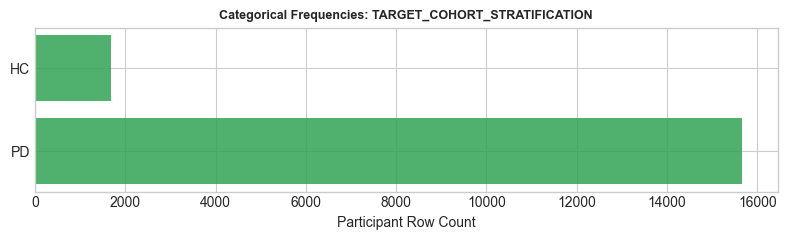

In [13]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MOTOR_Modified_Schwab___England_Activities_of_Daily_Living_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MOTOR/Modified_Schwab___England_Activities_of_Daily_Living_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MOTOR_Modified_Schwab___England_Activities_of_Daily_Living_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MOTOR_Modified_Schwab___England_Activities_of_Daily_Living_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MOTOR_Modified_Schwab___England_Act", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (1 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [14]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (1 < 2)
Features Evaluated: 1 included, 8 excluded

Excluded Variables Sample:


,feature_name,reason
0,REC_ID,"Identifier, date, visit, demographic, instrume..."
1,PATNO,"Identifier, date, visit, demographic, instrume..."
2,EVENT_ID,"Identifier, date, visit, demographic, instrume..."
3,PAG_NAME,"Identifier, date, visit, demographic, instrume..."
4,INFODT,"Identifier, date, visit, demographic, instrume..."
5,ORIG_ENTRY,"Identifier, date, visit, demographic, instrume..."
6,LAST_UPDATE,"Identifier, date, visit, demographic, instrume..."
7,TARGET_COHORT_STRATIFICATION,"Identifier, date, visit, demographic, instrume..."


---
## 2.7. Unit: `Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026.csv` 
- **Unit Slug**: `MOTOR_Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026_csv`
- **Source Path**: `MOTOR/Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026.csv`
- **Committed Unit Artifact**: [`MOTOR_Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026_csv.json`](../EDA/outputs/reports/units/MOTOR_Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Standardized quality of life assessment focused on lower limb mobility, gait stability, and transfers.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: MOTOR/Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 6,216 analyzed rows x 16 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 14,826 (4,822 participants)
  - PD Retained:  5,082 rows (1,432 participants)
  - HC Retained:  1,134 rows (256 participants)
  - Non-Target Excluded: 8,291 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  319 rows

Exact Variable Schema & Storage Types (16 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"6,216",Identifier
1,PATNO,int64,0,0.0%,"1,688",Identifier
2,EVENT_ID,object,0,0.0%,18,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,92,Date / Timestamp / Visit
5,NQMOB37,int64,0,0.0%,5,Analytical Numeric Measurement
6,NQMOB30,int64,0,0.0%,5,Analytical Numeric Measurement
7,NQMOB26,int64,0,0.0%,5,Analytical Numeric Measurement
8,NQMOB32,float64,2,0.0%,5,Analytical Numeric Measurement
9,NQMOB25,float64,1,0.0%,5,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,8
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 6 / 99,456 (0.01%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (4 total, top 8):


,name,missing_count,missing_percent,variable_role
8,NQMOB32,2,0.0%,Analytical Numeric Measurement
12,NQMOB28,2,0.0%,Analytical Numeric Measurement
9,NQMOB25,1,0.0%,Analytical Numeric Measurement
11,NQMOB31,1,0.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"5,082"
1,HC,"1,134"



Numeric Summaries & Outlier Diagnostics (8 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,NQMOB37,4.725,0.611,1.0,5.0,5.0,-2.555,Strongly skewed (negative),"1,270",79
1,NQMOB30,4.706,0.666,1.0,5.0,5.0,-2.819,Strongly skewed (negative),"1,312",136
2,NQMOB26,4.464,0.765,1.0,5.0,5.0,-1.442,Strongly skewed (negative),154,154
3,NQMOB32,4.651,0.691,1.0,5.0,5.0,-2.215,Strongly skewed (negative),"1,553",125
4,NQMOB25,4.534,0.775,1.0,5.0,5.0,-1.966,Strongly skewed (negative),185,185
5,NQMOB33,4.589,0.920,1.0,5.0,5.0,-2.557,Strongly skewed (negative),"1,390",193
6,NQMOB31,4.265,1.047,1.0,5.0,5.0,-1.522,Strongly skewed (negative),524,212
7,NQMOB28,4.599,0.903,1.0,5.0,5.0,-2.574,Strongly skewed (negative),"1,373",172


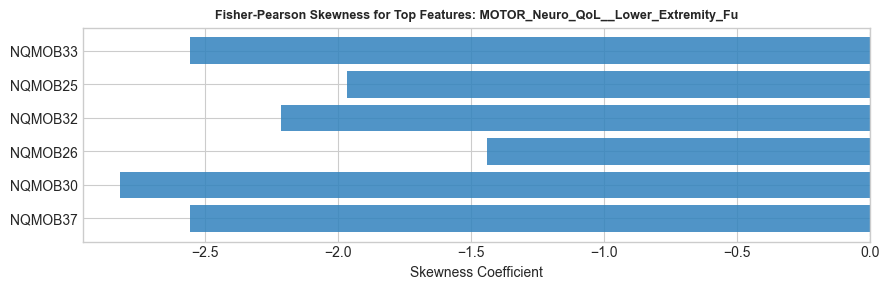

In [15]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MOTOR_Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MOTOR/Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MOTOR_Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MOTOR_Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MOTOR_Neuro_QoL__Lower_Extremity_Fu", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `8` continuous analytical measurements
- **Excluded Features**: `8` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `60.2%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,432 participants
  - Initial Eligible HC: 256 participants
  - Class-Balanced Fit Size: 256 participants per class (Total Fit N=512)
  - Total Projected Participants: 1,688


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,60.18%,60.18%
1,PC2,8.41%,68.59%
2,PC3,6.78%,75.36%
3,PC4,6.29%,81.65%
4,PC5,6.04%,87.69%



Top PC1 Feature Loadings:


,feature_name,loading
0,NQMOB26,0.3788
1,NQMOB32,0.3673
2,NQMOB37,0.3651
3,NQMOB31,0.3577
4,NQMOB33,0.3500


Scree & Eigenvector Loadings Plot:


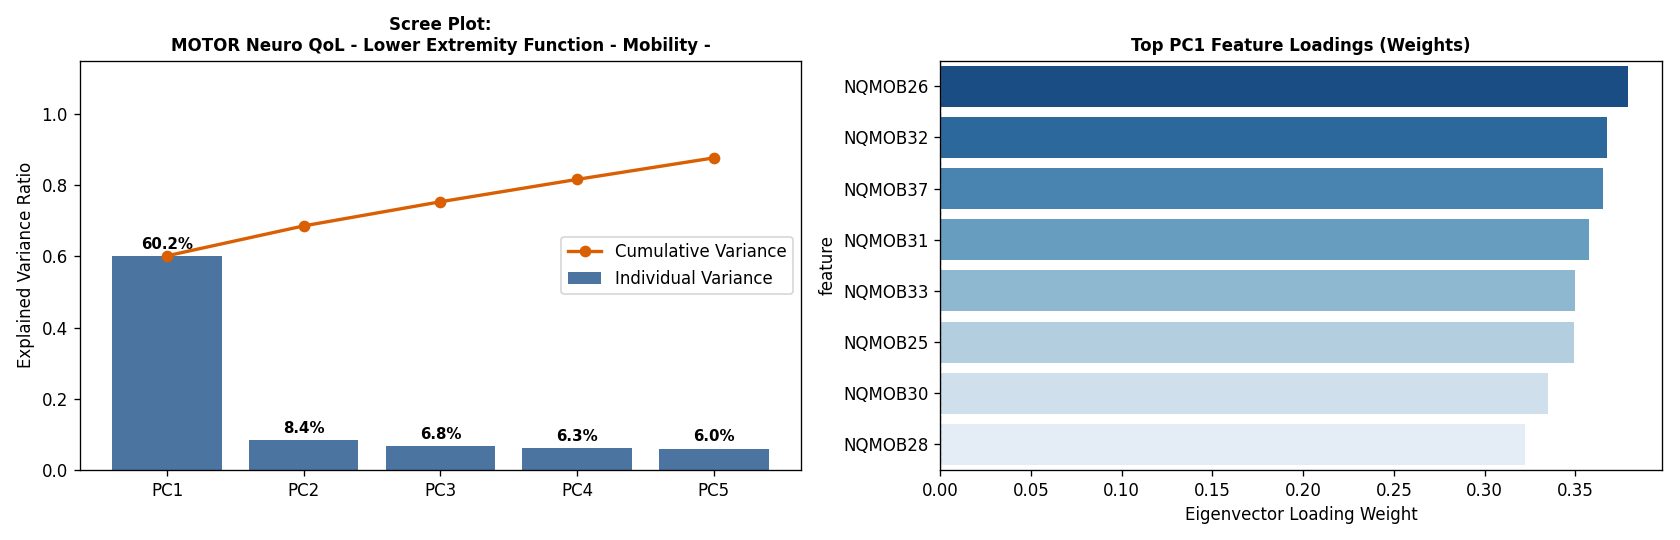

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


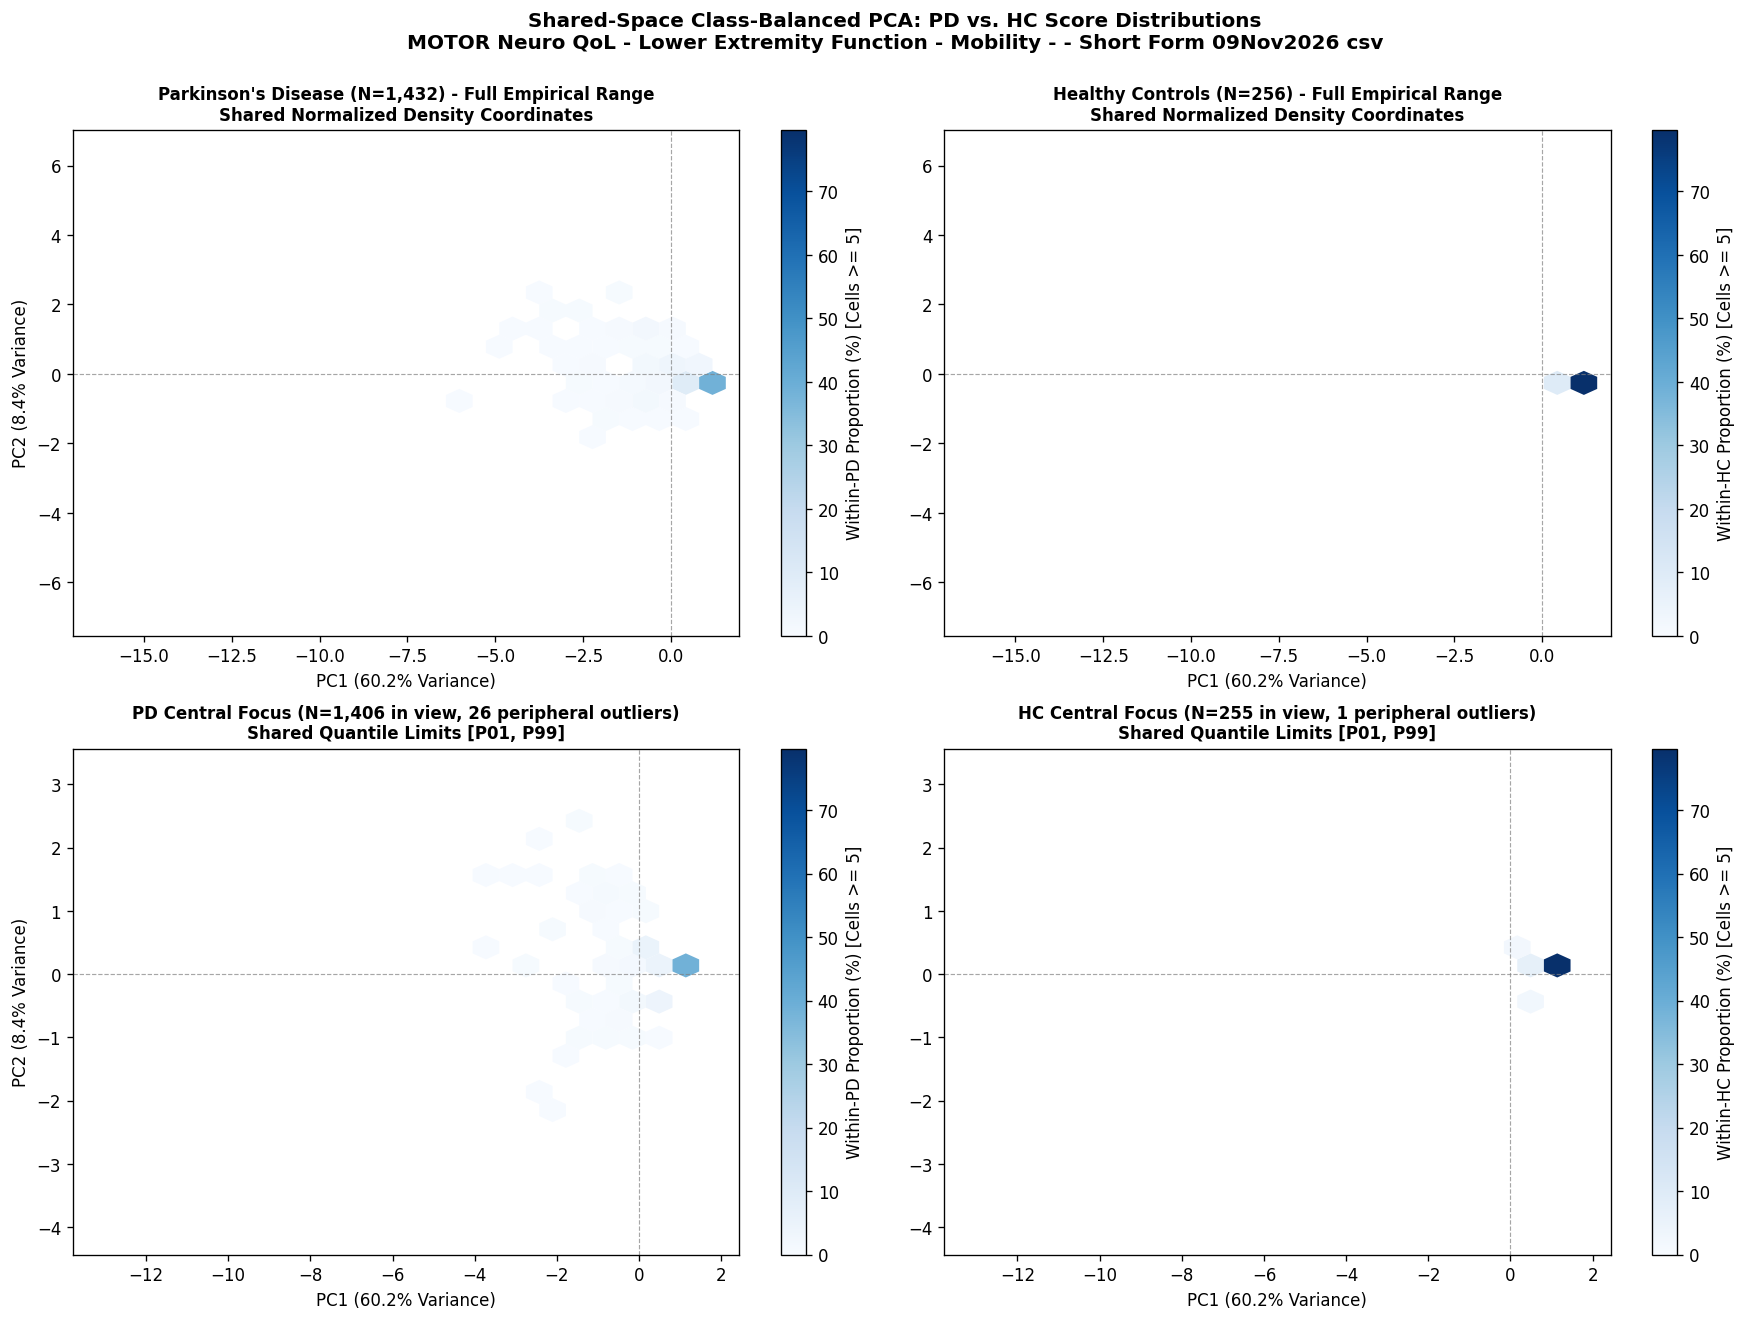

In [16]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/MOTOR_Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/MOTOR_Neuro_QoL__Lower_Extremity_Function__Mobility__-_Short_Form_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.8. Unit: `Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026.csv` 
- **Unit Slug**: `MOTOR_Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026_csv`
- **Source Path**: `MOTOR/Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026.csv`
- **Committed Unit Artifact**: [`MOTOR_Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026_csv.json`](../EDA/outputs/reports/units/MOTOR_Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Supporting` | **Role**: `Standardized quality of life assessment measuring fine motor control, hand function, and daily upper extremity tasks.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: MOTOR/Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 6,214 analyzed rows x 16 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['REC_ID'], ['PATNO', 'EVENT_ID'], ['PATNO', 'INFODT']]

Target Cohort Filtering Denominators:
  - Initial Rows: 14,823 (4,822 participants)
  - PD Retained:  5,080 rows (1,432 participants)
  - HC Retained:  1,134 rows (256 participants)
  - Non-Target Excluded: 8,290 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  319 rows

Exact Variable Schema & Storage Types (16 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,REC_ID,object,0,0.0%,"6,214",Identifier
1,PATNO,int64,0,0.0%,"1,688",Identifier
2,EVENT_ID,object,0,0.0%,18,Identifier
3,PAG_NAME,object,0,0.0%,1,Administrative Metadata
4,INFODT,object,0,0.0%,92,Date / Timestamp / Visit
5,NQUEX29,int64,0,0.0%,5,Analytical Numeric Measurement
6,NQUEX20,float64,1,0.0%,5,Analytical Numeric Measurement
7,NQUEX44,float64,1,0.0%,5,Analytical Numeric Measurement
8,NQUEX36,float64,2,0.0%,5,Analytical Numeric Measurement
9,NQUEX30,int64,0,0.0%,5,Analytical Numeric Measurement



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,8
Identifier,3
Administrative Metadata,2
Date / Timestamp / Visit,2
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 5 / 99,424 (0.01%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (4 total, top 8):


,name,missing_count,missing_percent,variable_role
8,NQUEX36,2,0.0%,Analytical Numeric Measurement
6,NQUEX20,1,0.0%,Analytical Numeric Measurement
7,NQUEX44,1,0.0%,Analytical Numeric Measurement
12,NQUEX37,1,0.0%,Analytical Numeric Measurement



Categorical Variable Frequency Distributions (1 variables profiled):
  * Feature: TARGET_COHORT_STRATIFICATION (Distinct Categories: 2)


,category,row_count
0,PD,"5,080"
1,HC,"1,134"



Numeric Summaries & Outlier Diagnostics (8 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,NQUEX29,4.813,0.511,1.0,5.0,5.0,-3.314,Strongly skewed (negative),896,207
1,NQUEX20,4.816,0.493,1.0,5.0,5.0,-3.122,Strongly skewed (negative),905,198
2,NQUEX44,4.834,0.495,1.0,5.0,5.0,-3.748,Strongly skewed (negative),779,184
3,NQUEX36,4.659,0.641,1.0,5.0,5.0,-2.138,Strongly skewed (negative),80,80
4,NQUEX30,4.406,0.926,1.0,5.0,5.0,-1.576,Strongly skewed (negative),385,60
5,NQUEX28,4.718,0.618,1.0,5.0,5.0,-2.579,Strongly skewed (negative),"1,312",78
6,NQUEX33,4.747,0.615,1.0,5.0,5.0,-2.911,Strongly skewed (negative),"1,126",91
7,NQUEX37,4.798,0.583,1.0,5.0,5.0,-3.644,Strongly skewed (negative),871,259


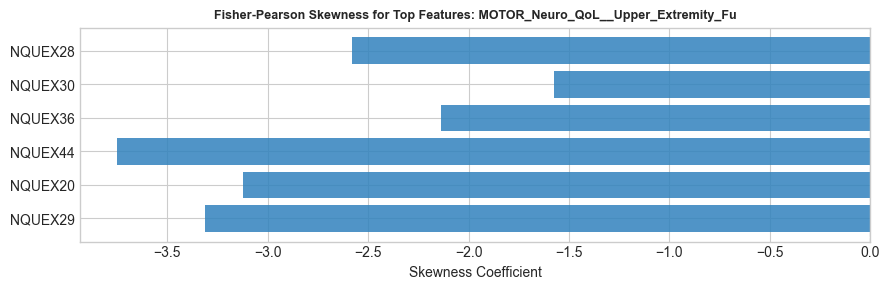

In [17]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "MOTOR_Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: MOTOR/Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to MOTOR_Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in MOTOR_Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: MOTOR_Neuro_QoL__Upper_Extremity_Fu", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `8` continuous analytical measurements
- **Excluded Features**: `8` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `50.4%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,432 participants
  - Initial Eligible HC: 256 participants
  - Class-Balanced Fit Size: 256 participants per class (Total Fit N=512)
  - Total Projected Participants: 1,688


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,50.37%,50.37%
1,PC2,11.47%,61.84%
2,PC3,10.44%,72.28%
3,PC4,7.12%,79.40%
4,PC5,6.18%,85.58%



Top PC1 Feature Loadings:


,feature_name,loading
0,NQUEX28,0.4047
1,NQUEX36,0.3788
2,NQUEX33,0.3775
3,NQUEX30,0.3627
4,NQUEX37,0.3582


Scree & Eigenvector Loadings Plot:


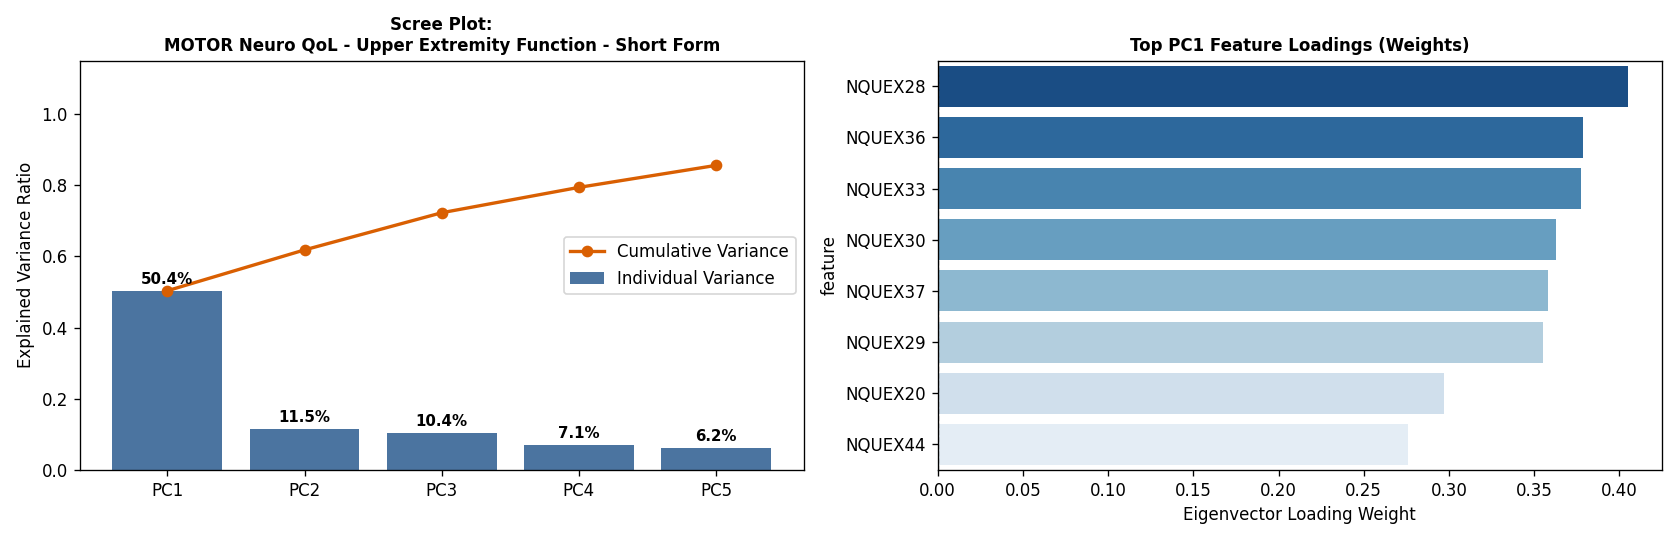

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


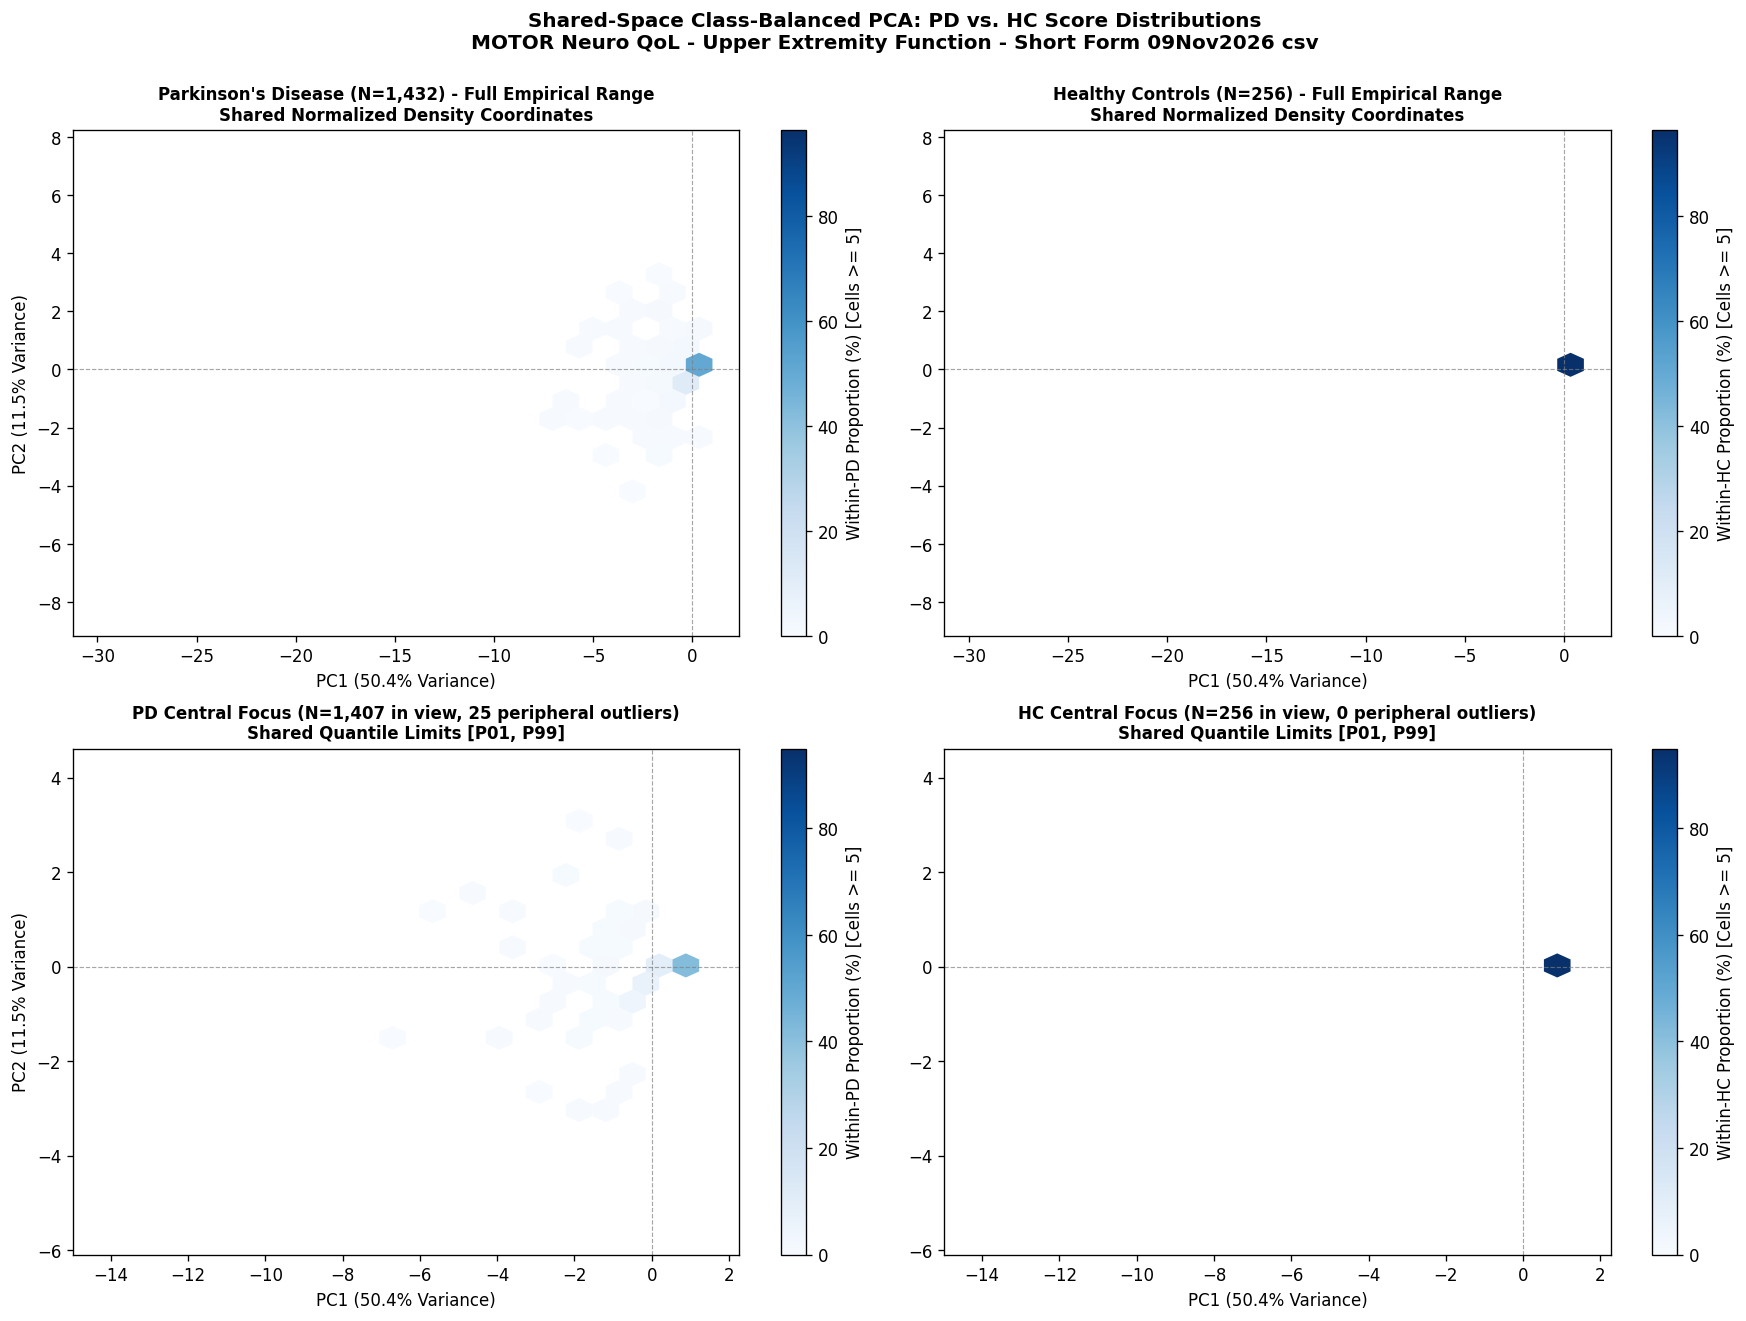

In [18]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/MOTOR_Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026_csv_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/MOTOR_Neuro_QoL__Upper_Extremity_Function_-_Short_Form_09Nov2026_csv_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 3. Modality Synthesis & Scientific Limitations

### Evidence-Bounded Findings
- **Data Coverage**: Analysis covered all 8 scoped analyzable unit(s) belonging to `Clinical Motor Examination & Impairment`.
- **Shared Coordinate Space**: All participant-level PCAs were estimated in a deterministically balanced coordinate space combining Parkinson's disease and healthy control cohorts, which reduces direct sample-count influence on component orientation.
- **Variance Patterns**: Scree and loading structures demonstrate dominant sources of numeric variance within the retained continuous feature space for this modality.

### Methodological Limitations
1. **Unadjusted Covariates**: PCA projections represent unadjusted variance; age, sex, and disease duration effects are not regressed out.
2. **Missingness Imputation**: Median imputation fitted exclusively on the class-balanced training sample was applied to replace missing values in retained features (features with > 40% missingness excluded), preserving sample size rather than performing complete-case deletion.
3. **No Causal / Diagnostic Claims**: PCA scores reflect descriptive data geometry and must not be interpreted as validated diagnostic classifiers or clinical progression endpoints without formal hypothesis testing.